# Livrable 1 — Modélisation des tournées de livraison
**Projet CesiCDP / ADEME · CESI FISE A3 · Version de travail pour le check**  
le jj octobre 2026 · Groupe : S.E.T.

**Question centrale :** comment livrer tous les clients avec les camions disponibles, sans les surcharger, tout en réduisant la durée totale des tournées ?

Ce notebook présente le besoin, un modèle mathématique, la preuve de complexité et une méthode envisagée. Il ne prétend pas présenter un solveur réalisé ni des performances mesurées. La méthode est incluse conformément à la grille de check fournie, malgré son exclusion dans le descriptif du premier livrable.

**Lecture rapide :** lire d'abord les phrases en gras et les schémas. Les formules précisent ensuite le sens des phrases. Les références [1] à [5] sont regroupées en fin de document.

## 1. Besoin et périmètre
CesiCDP répond à un appel de l'ADEME sur la mobilité. Nous étudions l'organisation des tournées de livraison : les camions partent d'un dépôt, servent les clients et reviennent au dépôt.

**Notre objectif est de minimiser la somme des durées des tournées, retours compris.** Ce n'est pas nécessairement l'heure à laquelle le dernier camion termine. Réduire les durées peut contribuer aux objectifs de mobilité, mais ce modèle ne calcule pas les émissions de CO₂.

La version de base retenue possède plusieurs camions de capacité identique : c'est le **CVRP**, problème de tournées avec capacité [1]. Les durées variant avec l'heure ajoutent une dimension de trafic temporel [3]. Nous n'ajoutons pas les fenêtres horaires chez les clients, option avancée de l'énoncé.

| Règle | Signification concrète |
|---|---|
| Tous les clients sont servis | Aucune commande n'est oubliée |
| Une visite par client | La commande d'un client n'est pas partagée entre plusieurs camions |
| Départ et retour au dépôt | Chaque tournée forme un trajet fermé |
| Capacité respectée | La quantité chargée ne dépasse pas la capacité du camion |
| Au plus les camions disponibles | Nous pouvons laisser un camion inutilisé |
| Trafic pris en compte | La durée d'un déplacement dépend de son heure de départ |

**Hypothèses proposées :** un seul dépôt ; une seule tournée par camion ; départ commun à une heure fixée ; demandes connues et strictement positives ; livraisons uniquement ; pas de pause ni d'attente volontaire ; temps de service négligés dans cette première version. Ces choix ne sont pas tous imposés par le sujet : ils doivent être validés au check.

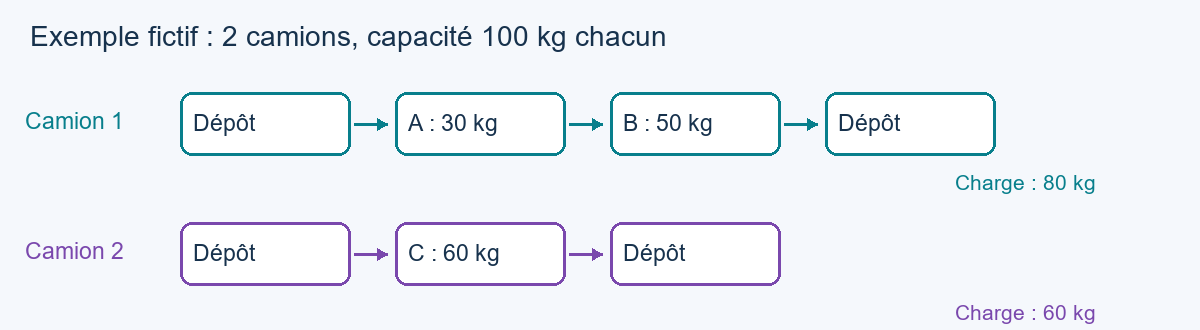

## 2. Données : ce que nous connaissons avant de choisir
| Symbole | Donnée | Exemple fictif |
|---|---|---|
| $0$ | Le dépôt | Entrepôt central |
| $C=\{1,\ldots,n\}$ | Liste des clients ; $n$ est leur nombre | A, B, C |
| $q_i$ | Quantité demandée par le client $i$ | A demande 30 kg |
| $Q$ | Capacité d'un camion | 100 kg |
| $k$ | Nombre de camions disponibles | 2 |
| $t_0$ | Heure commune de départ | 8 h |
| $\tau_{ij}(t)$ | Durée du trajet de $i$ vers $j$ en partant à l'heure $t$ | 10 min à 8 h, 18 min à 8 h 30 |

**Les unités doivent permettre une comparaison :** si la capacité est en kilogrammes, les demandes sont aussi en kilogrammes. Les durées sont exprimées en minutes. Les valeurs ci-dessus illustrent le modèle ; ce ne sont pas les données officielles du projet.

On représente les lieux par des sommets et les déplacements autorisés par des arcs orientés. Aller de A à B peut prendre un temps différent du retour. Un arc résume un trajet routier entre deux lieux à desservir ; traverser une zone ne signifie pas y effectuer une livraison.

Le trafic est une prévision connue, indépendante des choix de nos quelques camions. Les fonctions de durée sont fournies sous une forme finie calculable efficacement, par exemple des données par tranches horaires. Leur calcul doit rester cohérent lors du passage d'une tranche à l'autre [3].

**Contrôles préalables :** si un client demande plus que $Q$, il ne peut pas être servi sous nos hypothèses. Si la demande totale dépasse $kQ$, les camions ne suffisent pas. L'inverse ne garantit pas que les commandes puissent être réparties : ces tests sont nécessaires, pas suffisants.

## 3. Choix de modélisation : sélectionner des tournées complètes
**Une décision vaut 1 si nous choisissons une tournée, et 0 sinon.** Cette formulation par tournées, de type partitionnement [1], est choisie pour rendre le modèle lisible. Une formulation avec une variable par arc serait une autre possibilité.

Une tournée candidate $r$ est une liste ordonnée :
$$r=(0,i_1,i_2,\ldots,i_m,0).$$
Cela signifie : dépôt, clients dans cet ordre, retour au dépôt. Elle contient au moins un client, sans répétition. Tous ses déplacements doivent être autorisés et sa charge doit respecter :
$$\sum_{h=1}^{m}q_{i_h}\le Q.$$
**NB :** le symbole $\sum$ signifie « additionner ». Ici, on additionne les commandes des clients de cette tournée.

On appelle $R$ l'ensemble de **toutes** les tournées respectant ces règles. Le départ au dépôt, le retour, l'absence de visites répétées et la capacité sont donc déjà imposés dans la définition de $R$.

### Durée d'une tournée avec trafic
On avance dans la liste des clients, en calculant l'heure d'arrivée après chaque déplacement. Avec $i_0=i_{m+1}=0$ :
$$T_0=t_0,\qquad T_{h+1}=T_h+\tau_{i_h,i_{h+1}}(T_h),\quad h=0,\ldots,m.$$
La durée complète est $c_r=T_{m+1}-t_0$.

**Exemple fictif :** départ à 8 h ; dépôt–A dure 10 min ; on repart de A à 8 h 10 et utilise la durée A–B correspondant à 8 h 10, puis on calcule le retour depuis B. Nous ne figeons pas tous les trajets au trafic de 8 h.

Pour une tournée et une heure de départ fixées, $c_r$ est une donnée calculée avant sa sélection. Le coût peut donc tenir compte du trafic tout en restant un coefficient constant dans le PLNE. Nous ne choisissons pas les heures de départ et n'autorisons pas l'attente volontaire dans cette version.

## 4. Programme linéaire en nombres entiers (PLNE)
**Objectif : choisir des tournées qui servent chacun exactement une fois, avec au plus $k$ camions, pour la plus petite durée totale.**

| Symbole | Signification |
|---|---|
| $z_r\in\{0,1\}$ | 1 si la tournée $r$ est choisie ; 0 sinon |
| $a_{ir}$ | 1 si le client $i$ apparaît dans la tournée $r$ ; 0 sinon. C'est une donnée |
| $c_r$ | Durée calculée de cette tournée, retour et trafic compris |

### Objectif
$$\min\ \sum_{r\in R}c_rz_r.$$
On additionne uniquement les durées des tournées choisies : multiplier par 0 élimine une tournée, multiplier par 1 la conserve.

### Chaque client est servi exactement une fois
$$\sum_{r\in R}a_{ir}z_r=1\qquad\text{pour chaque client }i\in C.$$
Pour un client donné, exactement une des tournées qui le visitent doit être choisie.

### Nombre de camions disponibles
$$\sum_{r\in R}z_r\le k.$$
Chaque tournée choisie utilise un camion. Les véhicules étant identiques, il suffit ensuite de leur attribuer les tournées sélectionnées.

### Décisions indivisibles
$$z_r\in\{0,1\}\qquad\text{pour toute tournée }r\in R.$$
Nous ne pouvons pas choisir « la moitié d'une tournée ».

**Pourquoi est-ce un PLNE ?** L'objectif et les contraintes sont des sommes de variables multipliées par des coefficients connus. Les variables sont binaires, donc entières.

**Où sont les autres contraintes ?** Capacité, arcs autorisés, départ et retour au dépôt, absence de répétition et de sous-tournée déconnectée sont garantis par la définition des tournées de $R$. Ils ne sont pas oubliés.

**Limite importante :** $R$ peut être extrêmement grand. Cette formulation est exacte pour les hypothèses retenues si toutes les tournées admissibles sont disponibles. Avec seulement une liste partielle, le modèle est restreint : son optimum n'est pas nécessairement l'optimum du problème complet. Pour plusieurs milliers de clients, nous ne proposons pas d'énumérer $R$ ; l'heuristique décrite plus loin manipule directement quelques tournées.

## 5. Vérification sur le petit exemple
**Ce contrôle illustre les contraintes ; il ne démontre pas un optimum.**

| Tournée choisie | Clients | Charge | Capacité |
|---|---|---:|---:|
| Dépôt → A → B → Dépôt | A et B | 30 + 50 = 80 kg | 100 kg |
| Dépôt → C → Dépôt | C | 60 kg | 100 kg |

Chaque client apparaît une fois ; les deux charges sont autorisées ; deux camions suffisent. Pour conclure sur la durée, il faut encore calculer les trajets selon les horaires. Un chemin dessiné n'est pas, à lui seul, une preuve d'optimalité.

La cellule suivante est un contrôle pédagogique exécutable avec Python seul. Elle utilise des durées fictives par tranches de 15 minutes, pas des mesures routières.

In [1]:
clients = {"A": 30, "B": 50, "C": 60}
capacite, nombre_camions = 100, 2
tournees = [["D", "A", "B", "D"], ["D", "C", "D"]]
base = {("D", "A"): 10, ("A", "B"): 12,
        ("B", "D"): 10, ("D", "C"): 14, ("C", "D"): 14}

def duree(i, j, minute):
    # Prévision fictive : 2 minutes de plus par tranche de 15 min.
    return base[i, j] + 2 * (minute // 15)

def verifier(routes):
    assert len(routes) <= nombre_camions, "Trop de camions"
    visites = []
    total = 0
    for route in routes:
        assert route[0] == route[-1] == "D", "Dépôt incorrect"
        visites.extend(route[1:-1])
        charge = sum(clients[c] for c in route[1:-1])
        assert charge <= capacite, "Camion surchargé"
        minute = 0  # Minutes écoulées depuis le départ commun.
        for i, j in zip(route, route[1:]):
            assert (i, j) in base, "Déplacement absent des données"
            minute += duree(i, j, minute)
        total += minute
        print(" → ".join(route), f": {charge} kg, {minute} min")
    assert sorted(visites) == sorted(clients), "Client oublié ou répété"
    print(f"Solution admissible ; durée totale : {total} min.")
    print("Optimalité non démontrée.")
    return total

total = verifier(tournees)
assert total == 62


D → A → B → D : 80 kg, 34 min
D → C → D : 60 kg, 28 min
Solution admissible ; durée totale : 62 min.
Optimalité non démontrée.


## 6. Étude de complexité
### 6.1 La question de décision
**Existe-t-il au plus k tournées qui servent tous les clients, respectent les capacités et dont la durée totale est au plus K ?**

K est une limite donnée en entrée. Répondre OUI ne demande pas de prouver que les tournées sont optimales.

### 6.2 Pourquoi le problème est dans NP
Le certificat est la liste ordonnée des clients de chaque tournée. Nous vérifions les visites uniques, les arcs autorisés, les charges, le nombre de camions, les retours et la durée totale.

Il y a au plus n tournées non vides et chaque client apparaît une fois. La description des tournées est donc de taille polynomiale. Avec des durées données sous une représentation finie permettant des calculs en temps polynomial, ces contrôles se font en temps polynomial dans la taille des données, y compris leur encodage numérique. **La version de décision appartient donc à NP.**

Cela concerne les données initiales du problème ; il n'est pas nécessaire de construire l'immense liste R pour vérifier une proposition.

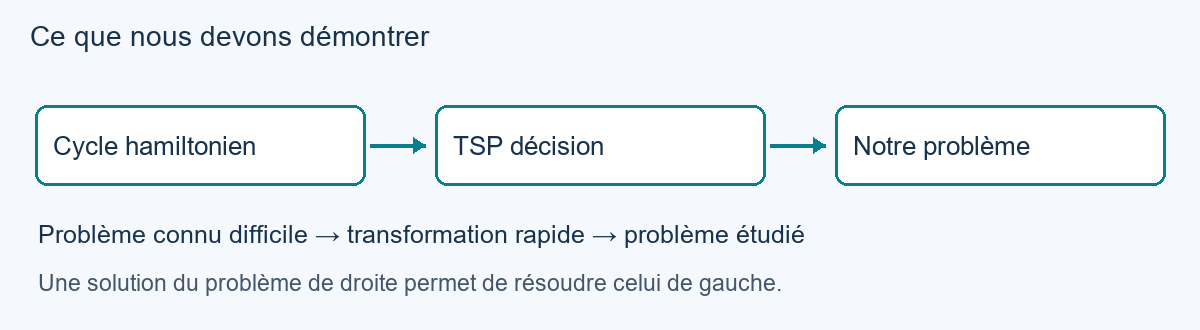

### 6.3 Pourquoi le problème est NP-difficile
**Le sens de la preuve compte : nous transformons un problème déjà connu difficile vers notre problème.**

**Étape A — Cycle hamiltonien vers TSP décision.** Le problème du cycle hamiltonien, connu NP-complet [2], demande s'il existe un cycle visitant chaque sommet exactement une fois. À partir d'un graphe de N sommets, on construit un graphe complet : coût 1 pour une liaison existante, coût 2 pour une liaison ajoutée. On fixe la limite à N.

• Si le graphe initial possède un cycle hamiltonien, ses N liaisons coûtent chacune 1 : la tournée coûte N.  
• Si une tournée du nouveau graphe coûte au plus N, ses N liaisons doivent toutes coûter 1. Elle correspond donc à un cycle hamiltonien du graphe initial.

La construction examine au plus un nombre quadratique de paires : elle est polynomiale. Les coûts 1 et 2 respectent aussi l'inégalité triangulaire : une liaison directe coûte au plus 2, passer par un troisième sommet coûte au moins 1 + 1. La difficulté existe donc même dans le cas métrique.

**Étape B — TSP décision vers notre problème de livraison.** On choisit un sommet comme dépôt et les autres comme clients. On fixe un seul camion, une demande de 1 par client et une capacité égale au nombre de clients. On utilise les coûts du TSP comme durées, constantes quelle que soit l'heure, et on garde la même limite K.

Une tournée TSP de coût au plus K existe **si et seulement si** une solution de livraison de durée au plus K existe dans cette instance. La capacité ne bloque aucune tournée ; le camion doit visiter tous les clients et revenir au dépôt. La transformation est polynomiale.

Le problème avec trafic contient le cas sans variation de trafic. Il est donc au moins aussi difficile que ce cas particulier. Ce raisonnement utilise l'hypothèse que k est une donnée pouvant valoir 1.

### 6.4 Conclusion
**Notre problème de décision est NP-complet : il est dans NP et NP-difficile. Le problème d'optimisation est NP-difficile.**

Cela ne signifie pas qu'une petite instance est impossible à résoudre. Cela ne prouve pas non plus que tout algorithme doit prendre un temps exponentiel. Aucun algorithme exact polynomial général n'est connu ; en trouver un pour ce problème impliquerait P = NP [2, 5].

## 7. Méthode de résolution envisagée
**Proposition à discuter avec le groupe : insertion gloutonne, puis recherche taboue.** Le choix est motivé par les décisions faciles à représenter : déplacer un client, échanger deux clients, modifier l'ordre d'une tournée. La recherche taboue est une méthode étudiée pour les tournées de véhicules [4]. Nous proposons une adaptation simplifiée, pas une reproduction de TABUROUTE.

### Construire une première solution
Créer au plus k listes de livraison. Examiner d'abord les commandes les plus grandes. Pour chaque client, tester les positions d'insertion dans les tournées dont la capacité restante suffit. Retenir celle qui augmente le moins la durée totale, recalculée avec le trafic.

Si un client ne peut pas être inséré, essayer d'autres ordres de construction, dans un budget fixé. Un échec de cette heuristique ne prouve pas que l'instance est impossible. Il faut signaler « aucune solution initiale trouvée » ; ne pas ajouter un camion au-delà de k.

### Améliorer la solution : le voisinage
Un voisin est une organisation obtenue par une petite modification :

| Modification | Exemple | Contrôle |
|---|---|---|
| Déplacement | Retirer A d'une tournée et l'insérer dans une autre | Capacités, unicité, arcs |
| Échange | Échanger A et C entre deux tournées | Capacités, arcs |
| Réorganisation interne | Changer l'ordre de deux clients d'un camion | Arcs, nouvelles heures et durées |

**Avec le trafic, on recalcule les horaires des tournées modifiées à partir de l'heure de départ.** Un calcul fondé uniquement sur quelques distances fixes ne suffit pas.

### Principe de la recherche taboue
1. Conserver la meilleure solution trouvée.
2. Choisir le meilleur voisin autorisé, même s'il dégrade temporairement la durée.
3. Interdire pendant quelques itérations le mouvement inverse, pour éviter les allers-retours immédiats.
4. Autoriser une exception si un mouvement interdit améliore la meilleure solution connue : c'est l'aspiration.
5. S'arrêter au budget de temps ou d'itérations fixé ; rendre la meilleure solution admissible conservée.

Dans notre première version, seules les solutions respectant toutes les contraintes sont acceptées. Si aucun mouvement autorisé n'existe, effectuer un redémarrage ou arrêter selon le budget. Les paramètres (durée d'interdiction, redémarrages, budget) restent à choisir expérimentalement. Cette restriction aux solutions admissibles peut limiter l'exploration ; l'article [4] autorise aussi des solutions non admissibles, ce que nous ne reprenons pas ici.

### Pourquoi conserver aussi le modèle exact ?
Le PLNE décrit rigoureusement le besoin et peut servir de référence sur de petites instances. Résoudre sa relaxation continue ne suffit pas : les variables pourraient être fractionnaires. Un solveur entier doit trouver une solution entière et prouver son optimalité. La recherche taboue cherche une bonne solution sous budget, sans garantie d'optimum.

**Aucune performance n'est annoncée :** le traitement de milliers de clients reste un objectif à tester. Examiner tous les voisins peut être trop lent ; limiter les candidats sera une piste, à mesurer ensuite.

## 8. Limites et décisions à valider au check
| Point | Proposition actuelle / travail restant |
|---|---|
| Nombre de véhicules | Au plus k ; confirmer qu'utiliser exactement k n'est pas imposé |
| Exploitation | Une tournée par camion, départ commun fixé |
| Livraison | Commandes indivisibles, pas de collecte ni de temps de service |
| Trafic | Fonctions de durée selon l'heure ; préciser la source et le format des données |
| Horaires clients | Pas de fenêtres de livraison dans cette version |
| Modèle PLNE | Formulation par tournées ; demander si le tuteur exige une formulation par arcs |
| Résolution | Recherche taboue proposée, choix collectif non encore arrêté |
| Résultats | Aucun benchmark réalisé dans ce check |

Le livrable final ajoutera l'implémentation, le plan d'expérience, les comparaisons sur au moins 20 instances et les références VRPLIB. Les instances statiques permettront d'abord de vérifier le cas sans trafic. Une meilleure solution connue n'est pas forcément un optimum prouvé : le gap doit nommer correctement sa référence.

## 9. Ce que nous avons établi
Nous avons défini le besoin, les hypothèses et un PLNE qui sélectionne des tournées admissibles. Les durées sont calculées selon le trafic avant la sélection. Nous avons démontré la NP-complétude de la version de décision et proposé une méthode d'amélioration adaptée. Le check doit maintenant valider les hypothèses et le modèle avant l'implémentation.

## 10. Références bibliographiques
Les explications et exemples sont rédigés pour ce notebook ; les sources suivantes soutiennent les notions et les choix. Les hypothèses locales et l'adaptation proposée de la méthode ne sont pas des résultats attribués à ces auteurs.

**[1]** Toth, P. et Vigo, D. (dir.), 2014. *Vehicle Routing: Problems, Methods, and Applications*, 2e éd., SIAM. [DOI : 10.1137/1.9781611973594](https://doi.org/10.1137/1.9781611973594). Ouvrage de référence sur les variantes, formulations et méthodes du VRP, notamment les formulations par tournées.

**[2]** Karp, R. M., 1972. « Reducibility Among Combinatorial Problems ». *Complexity of Computer Computations*, p. 85–103. [DOI : 10.1007/978-1-4684-2001-2_9](https://doi.org/10.1007/978-1-4684-2001-2_9). Référence fondatrice pour les réductions et les problèmes NP-complets, dont le cycle hamiltonien.

**[3]** Ichoua, S., Gendreau, M. et Potvin, J.-Y., 2003. « Vehicle dispatching with time-dependent travel times ». *European Journal of Operational Research*, 144(2), p. 379–396. [DOI : 10.1016/S0377-2217(02)00147-9](https://doi.org/10.1016/S0377-2217(02)00147-9). Référence pour la prise en compte de temps de trajet dépendant de l'heure. Le modèle de trafic précis de cet article n'est pas reproduit ici.

**[4]** Gendreau, M., Hertz, A. et Laporte, G., 1994. « A Tabu Search Heuristic for the Vehicle Routing Problem ». *Management Science*, 40(10), p. 1276–1290. [DOI : 10.1287/mnsc.40.10.1276](https://doi.org/10.1287/mnsc.40.10.1276). Référence pour la recherche taboue appliquée aux tournées ; notre méthode envisagée est simplifiée.

**[5]** Clay Mathematics Institute. *P vs NP*. [Présentation du problème ouvert](https://www.claymath.org/millennium/p-vs-np/). Source institutionnelle complémentaire sur le statut de P = NP.

**Consignes pédagogiques :** CESI, sujet du projet Algorithmique et optimisation 2026–2027 et grille « Livrable Modélisation » fournis au groupe. [Sujet CESI](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/_5_-_Projet.html). La grille demande une méthode de résolution ; ce notebook la présente, à titre de proposition.

## 11. Guide de reprise pour la réunion
**À expliquer dans cet ordre :**
1. Nous choisissons quelles tournées effectuer, avec quels clients et dans quel ordre.
2. Chaque client est servi une fois et aucun camion n'est surchargé.
3. Nous minimisons la somme des durées, retours compris ; le trafic intervient dans leur calcul.
4. Le modèle exact peut avoir trop de tournées possibles pour toutes les énumérer.
5. La difficulté est démontrée par réduction ; nous proposons donc une recherche taboue sous budget.

**À compléter avant le dépôt :** noms du groupe, validation des hypothèses, accord sur la méthode et éventuelles corrections du tuteur.

**Utilisation du fichier :** le fichier `.ipynb` est le notebook modifiable et partageable. Dans Jupyter, ouvrir le fichier puis double-cliquer sur une cellule de texte pour la modifier ; `Maj + Entrée` affiche son contenu. La cellule Python est facultative pour lire le document. Les deux schémas et son résultat sont déjà intégrés. La version HTML permet de lire sans installer Jupyter (connexion nécessaire pour l'affichage des formules via MathJax).